## 1.4 Classical grid baseline
Run  the 0.1 and 0.2 pipelines beforehand. This notebook uses HOG and SIFT to predict fracture probability and four box distances on a 32 by 16 grid, with 16 by 16 pixel cells. 

In [1]:

%pip install opencv-python joblib matplotlib numpy pandas ipython scikit-image scikit-learn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from time import perf_counter

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from skimage.feature import hog
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

PROCESSED_DIR = ROOT / 'data' / 'processed'
INTERIM_DIR = ROOT / 'data' / 'interim'
NOTEBOOK_DIR = ROOT / 'models' / '1.4_grid-baseline_zahra'

SEEDS = [42]
TRAIN_SETS = ['all', 'clean', 'all-castpairs']
CELL_SIZE = 16
GRID_ROWS, GRID_COLS = 32, 16
N_CELLS = GRID_ROWS * GRID_COLS
IMAGE_SHAPE = (GRID_ROWS * CELL_SIZE, GRID_COLS * CELL_SIZE)
HOG_SIZE, SIFT_SIZE = 36, 128
NEGATIVES_PER_IMAGE = 40
GB_SETTINGS = dict(learning_rate=0.1, max_iter=200)
LR_C = 0.1
RIDGE_ALPHA = 10.0
MIN_DISTANCE, MAX_DISTANCE = 1, 400
PREDICT_BATCH_SIZE = 200

required_files = [
    'graz.csv', 'graz_256x512_u8.npy', 'graz_boxes.csv', 'graz_cell_targets.npz',
    'graz_cast_pairs.csv', 'graz_cast_pairs_256x512_u8.npy',
    'graz_cast_pairs_cell_targets.npz',
]
missing_files = [name for name in required_files if not (PROCESSED_DIR / name).is_file()]
assert not missing_files, f'Run 0.1 and 0.2 first. Missing from {PROCESSED_DIR}: {missing_files}'

## Load images and cell targets
The CSV rows, image arrays, and targets share the same order. The cast pairs only add training examples.

In [ ]:
def load_data(prefix):
    metadata = pd.read_csv(PROCESSED_DIR / f'{prefix}.csv')
    images = np.load(PROCESSED_DIR / f'{prefix}_256x512_u8.npy', mmap_mode='r')
    with np.load(PROCESSED_DIR / f'{prefix}_cell_targets.npz') as targets:
        objectness = targets['objectness']
        distances = targets['distances']

    assert images.shape == (len(metadata), *IMAGE_SHAPE)
    assert objectness.shape == (len(metadata), GRID_ROWS, GRID_COLS)
    assert distances.shape == (*objectness.shape, 4)
    return metadata, images, objectness, distances

graz, images, objectness, distances = load_data('graz')
pairs, pair_images, pair_objectness, pair_distances = load_data('graz_cast_pairs')
assert pairs['split'].eq('train').all()

train_rows = np.flatnonzero(graz['split'].eq('train'))
clean_rows = np.flatnonzero(graz['split'].eq('train') & graz['clean'].eq(1))
val_rows = np.flatnonzero(graz['split'].eq('val'))
test_rows = np.flatnonzero(graz['split'].eq('test'))
print(f'{len(train_rows)} train, {len(clean_rows)} clean train, {len(pairs)} cast crops')
print(f'{len(val_rows)} validation, {len(test_rows)} test')

14182 train, 7589 clean train, 7018 cast crops
3202 validation, 2943 test


## Extract HOG and SIFT
Extract both features in grid order. Write one image at a time to disk and reuse completed caches on later runs.

In [ ]:
def extract_features(images, prefix):
    started = perf_counter()
    hog_path = INTERIM_DIR / f'{prefix}_cell_hog.npy'
    sift_path = INTERIM_DIR / f'{prefix}_cell_sift.npy'
    hog_shape = (len(images), N_CELLS, HOG_SIZE)
    sift_shape = (len(images), N_CELLS, SIFT_SIZE)

    if not (hog_path.is_file() and sift_path.is_file()):
        INTERIM_DIR.mkdir(parents=True, exist_ok=True)
        hog_temp = hog_path.with_suffix('.tmp.npy')
        sift_temp = sift_path.with_suffix('.tmp.npy')
        hog_cache = np.lib.format.open_memmap(hog_temp, mode='w+', dtype=np.float32, shape=hog_shape)
        sift_cache = np.lib.format.open_memmap(sift_temp, mode='w+', dtype=np.uint8, shape=sift_shape)

        sift = cv2.SIFT_create()
        keypoints = [
            cv2.KeyPoint(CELL_SIZE * col + 8, CELL_SIZE * row + 8, CELL_SIZE, 0)
            for row in range(GRID_ROWS) for col in range(GRID_COLS)
        ]

        for i, image in enumerate(images):
            padded = np.pad(image, 8, mode='edge')
            blocks = hog(
                padded, orientations=9, pixels_per_cell=(CELL_SIZE, CELL_SIZE),
                cells_per_block=(2, 2), block_norm='L2-Hys', feature_vector=False,
            )
            assert blocks.shape == (GRID_ROWS, GRID_COLS, 2, 2, 9)
            kept, descriptors = sift.compute(image, keypoints)
            assert descriptors is not None and descriptors.shape == (N_CELLS, SIFT_SIZE)
            assert all(actual.pt == expected.pt for actual, expected in zip(kept, keypoints))
            hog_cache[i] = blocks.reshape(N_CELLS, HOG_SIZE)
            sift_cache[i] = descriptors
            if (i + 1) % 1000 == 0:
                print(f'{prefix}: {i + 1:,}/{len(images):,} images', flush=True)

        hog_cache.flush()
        sift_cache.flush()
        del hog_cache, sift_cache
        hog_temp.replace(hog_path)
        sift_temp.replace(sift_path)
        print(f'{prefix}: extracted features in {(perf_counter() - started) / 60:.1f} minutes')
    else:
        print(f'{prefix}: using cached features')

    hog_features = np.load(hog_path, mmap_mode='r')
    sift_features = np.load(sift_path, mmap_mode='r')
    assert hog_features.shape == hog_shape and hog_features.dtype == np.float32
    assert sift_features.shape == sift_shape and sift_features.dtype == np.uint8
    return hog_features, sift_features
features = extract_features(images, 'graz')
pair_features = extract_features(pair_images, 'graz_cast_pairs')

graz: using cached features
graz_cast_pairs: using cached features


## Sample training cells
Use every positive cell and up to 40 randomly sampled negatives per image. For cast crops, skip fully black negative cells. Use positive cells alone for the box regressors.

In [5]:
def sample_cells(rows, labels, rng, crop_images=None):
    image_indices, cell_indices, sampled_labels = [], [], []
    for row in rows:
        grid = labels[row].ravel()
        positive = np.flatnonzero(grid == 1)
        negative = np.flatnonzero(grid == 0)

        if crop_images is not None:
            patches = crop_images[row].reshape(GRID_ROWS, CELL_SIZE, GRID_COLS, CELL_SIZE)
            nonblack = patches.any(axis=(1, 3)).ravel()
            negative = negative[nonblack[negative]]

        selected = np.concatenate([
            positive,
            rng.choice(negative, size=min(NEGATIVES_PER_IMAGE, len(negative)), replace=False),
        ])
        image_indices.append(np.full(len(selected), row, dtype=np.intp))
        cell_indices.append(selected)
        sampled_labels.append(grid[selected])

    return np.concatenate(image_indices), np.concatenate(cell_indices), np.concatenate(sampled_labels)


def training_data(train_set, seed):
    rng = np.random.default_rng(seed)
    rows = clean_rows if train_set == 'clean' else train_rows
    sources = [(features, distances, sample_cells(rows, objectness, rng))]
    if train_set == 'all-castpairs':
        extra = sample_cells(np.arange(len(pairs)), pair_objectness, rng, pair_images)
        sources.append((pair_features, pair_distances, extra))

    n_samples = sum(len(sample[2]) for _, _, sample in sources)
    X = np.empty((n_samples, HOG_SIZE + SIFT_SIZE), dtype=np.float32)
    y = np.empty(n_samples, dtype=np.int8)
    box_targets = []
    start = 0

    for (hog_features, sift_features), box_grid, (row, cell, labels) in sources:
        for offset in range(0, len(labels), 50_000):
            batch = slice(offset, offset + 50_000)
            output = slice(start + offset, start + min(offset + 50_000, len(labels)))
            X[output, :HOG_SIZE] = hog_features[row[batch], cell[batch]]
            X[output, HOG_SIZE:] = sift_features[row[batch], cell[batch]]
        y[start:start + len(labels)] = labels
        positive = labels == 1
        box_targets.append(box_grid.reshape(-1, N_CELLS, 4)[row[positive], cell[positive]])
        start += len(labels)

    print(f'{train_set}: {(y == 1).sum():,} positive and {(y == 0).sum():,} negative cells')
    return X, y, np.concatenate(box_targets)

## Train and save predictions
Fit logistic regression with Ridge, and gradient boosting with one box regressor per distance. Save one folder per model, training set, and seed. For validation and test, predict every cell of the original images.

In [ ]:
def fit_models(model_name, seed, X, y, box_X, box_y):
    if model_name == 'lr':
        classifier = make_pipeline(
            StandardScaler(), LogisticRegression(C=LR_C, max_iter=500, random_state=seed),
        )
        box_models = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
        box_models.fit(box_X, box_y)
    else:
        classifier = HistGradientBoostingClassifier(random_state=seed, **GB_SETTINGS)
        box_models = []
        for side in range(4):
            regressor = HistGradientBoostingRegressor(random_state=seed, **GB_SETTINGS)
            regressor.fit(box_X, box_y[:, side])
            box_models.append(regressor)

    classifier.fit(X, y)
    return classifier, box_models


def save_predictions(path, rows, classifier, box_models):
    scores = np.empty((len(rows), GRID_ROWS, GRID_COLS), dtype=np.float32)
    predicted_boxes = np.empty((*scores.shape, 4), dtype=np.float32)
    hog_features, sift_features = features

    for start in range(0, len(rows), PREDICT_BATCH_SIZE):
        batch = slice(start, start + PREDICT_BATCH_SIZE)
        batch_rows = rows[batch]
        X = np.empty((len(batch_rows) * N_CELLS, HOG_SIZE + SIFT_SIZE), dtype=np.float32)
        X[:, :HOG_SIZE] = hog_features[batch_rows].reshape(-1, HOG_SIZE)
        X[:, HOG_SIZE:] = sift_features[batch_rows].reshape(-1, SIFT_SIZE)
        scores[batch] = classifier.predict_proba(X)[:, 1].reshape(-1, GRID_ROWS, GRID_COLS)

        if isinstance(box_models, list):
            boxes = np.column_stack([model.predict(X) for model in box_models])
        else:
            boxes = box_models.predict(X)
        predicted_boxes[batch] = np.clip(boxes, MIN_DISTANCE, MAX_DISTANCE).reshape(
            -1, GRID_ROWS, GRID_COLS, 4,
        )

    temp_path = path.with_suffix('.tmp.npz')
    np.savez_compressed(temp_path, rows=rows, scores=scores, distances=predicted_boxes)
    temp_path.replace(path)
run_folders = []
for seed in SEEDS:
    for train_set in TRAIN_SETS:
        X = None
        for model_name in ['lr', 'gb']:
            run_folder = NOTEBOOK_DIR / f'hog-sift-{model_name}_{train_set}_seed{seed}'
            run_folders.append(run_folder)
            val_path = run_folder / 'val_cell_predictions.npz'
            test_path = run_folder / 'test_cell_predictions.npz'
            model_path = run_folder / 'objectness_model.joblib'
            box_path = run_folder / 'box_regressors.joblib'
            if all(path.is_file() for path in (val_path, test_path, model_path, box_path)):
                print(f'{run_folder.name}: already complete')
                continue

            started = perf_counter()
            if X is None:
                X, y, box_y = training_data(train_set, seed)
                box_X = X[y == 1]

            val_path.unlink(missing_ok=True)
            run_folder.mkdir(parents=True, exist_ok=True)
            classifier, box_models = fit_models(model_name, seed, X, y, box_X, box_y)
            joblib.dump(classifier, model_path)
            joblib.dump(box_models, box_path)
            save_predictions(test_path, test_rows, classifier, box_models)
            save_predictions(val_path, val_rows, classifier, box_models)
            print(f'{run_folder.name}: {(perf_counter() - started) / 60:.1f} minutes', flush=True)

        if X is not None:
            del X, y, box_X, box_y

hog-sift-lr_all_seed42: already complete
hog-sift-gb_all_seed42: already complete
hog-sift-lr_clean_seed42: already complete
hog-sift-gb_clean_seed42: already complete
hog-sift-lr_all-castpairs_seed42: already complete
hog-sift-gb_all-castpairs_seed42: already complete


In [7]:
print("Runs with saved predictions:",
      len(list(NOTEBOOK_DIR.glob('*/val_cell_predictions.npz'))))

Runs with saved predictions: 6


## Check validation results
Compute cell AUC over labeled validation cells. Compare average validation score maps for fractured and normal images using the same color scale.

,run,validation_cell_auc
0,hog-sift-lr_all_seed42,0.9562
1,hog-sift-gb_all_seed42,0.9841
2,hog-sift-lr_clean_seed42,0.9373
3,hog-sift-gb_clean_seed42,0.9624
4,hog-sift-lr_all-castpairs_seed42,0.9559
5,hog-sift-gb_all-castpairs_seed42,0.9822


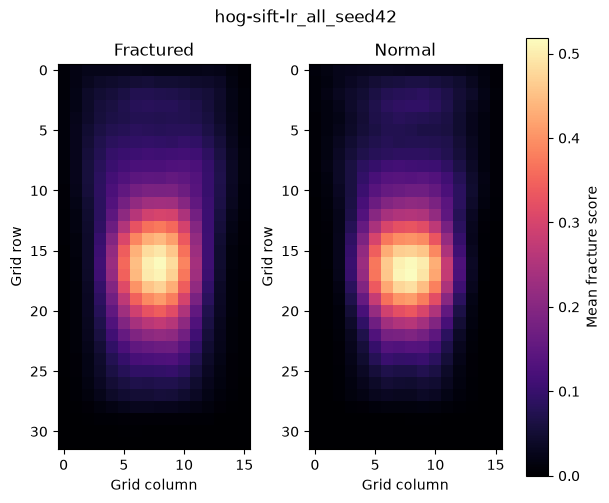

In [8]:
results = []
for run_folder in run_folders:
    with np.load(run_folder / 'val_cell_predictions.npz') as predictions:
        labels = objectness[predictions['rows']]
        scores = predictions['scores']
    labeled = labels != -1
    auc = roc_auc_score(labels[labeled], scores[labeled])
    results.append({'run': run_folder.name, 'validation_cell_auc': auc})

display(pd.DataFrame(results).round(4))

heatmap_run = run_folders[0]
with np.load(heatmap_run / 'val_cell_predictions.npz') as predictions:
    labels = graz.iloc[predictions['rows']]['label'].to_numpy()
    scores = predictions['scores']

fractured = scores[labels == 1].mean(axis=0)
normal = scores[labels == 0].mean(axis=0)
upper = max(fractured.max(), normal.max())

fig, axes = plt.subplots(1, 2, figsize=(6, 5), layout='constrained')
for ax, title, mean_scores in zip(axes, ['Fractured', 'Normal'], [fractured, normal]):
    heatmap = ax.imshow(mean_scores, cmap='magma', vmin=0, vmax=upper)
    ax.set(title=title, xlabel='Grid column', ylabel='Grid row')
fig.suptitle(heatmap_run.name)
fig.colorbar(heatmap, ax=axes, label='Mean fracture score')
plt.show()

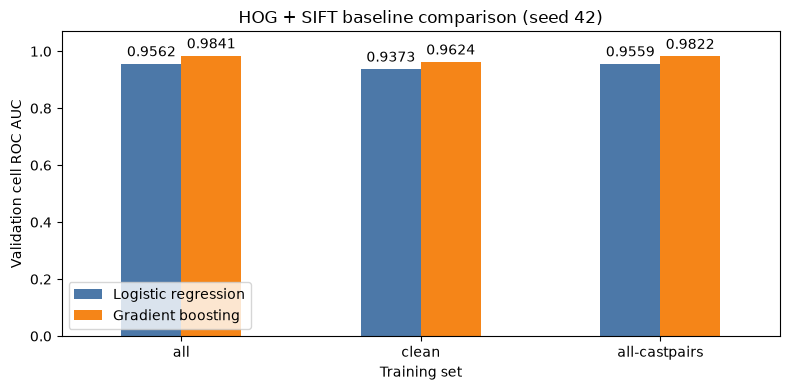

In [ ]:
auc = pd.DataFrame(results)
auc[['model', 'training_set']] = auc['run'].str.extract(
    r'hog-sift-(lr|gb)_(.+)_seed42$'
)
comparison = auc.pivot(
    index='training_set', columns='model', values='validation_cell_auc'
).reindex(index=['all', 'clean', 'all-castpairs'], columns=['lr', 'gb'])

comparison.columns = ['Logistic regression', 'Gradient boosting']
ax = comparison.plot.bar(figsize=(8, 4), color=['#4C78A8', '#F58518'])

ax.set(
    title='HOG + SIFT baseline comparison (seed 42)',
    xlabel='Training set',
    ylabel='Validation cell ROC AUC',
    ylim=(0, 1.07),
)
ax.tick_params(axis='x', rotation=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.4f', padding=3)
plt.tight_layout()
plt.show()

## Predict fracture or no fracture
Each validation X-ray has 512 cells, and the image is called a fracture when at least one cell exceeds 0.5. The maximum cell score is the image score used for ROC AUC. The cutoff sets the yes/no decision; ROC AUC evaluates the ranking over all thresholds.

,run,validation_cell_auc,image_auc,flagged_xrays,total_xrays
0,hog-sift-lr_all_seed42,0.9562,0.5125,3198,3202
1,hog-sift-gb_all_seed42,0.9841,0.8046,3200,3202
2,hog-sift-lr_clean_seed42,0.9373,0.4335,3123,3202
3,hog-sift-gb_clean_seed42,0.9624,0.6782,3164,3202
4,hog-sift-lr_all-castpairs_seed42,0.9559,0.4890,3197,3202
5,hog-sift-gb_all-castpairs_seed42,0.9822,0.7736,3200,3202


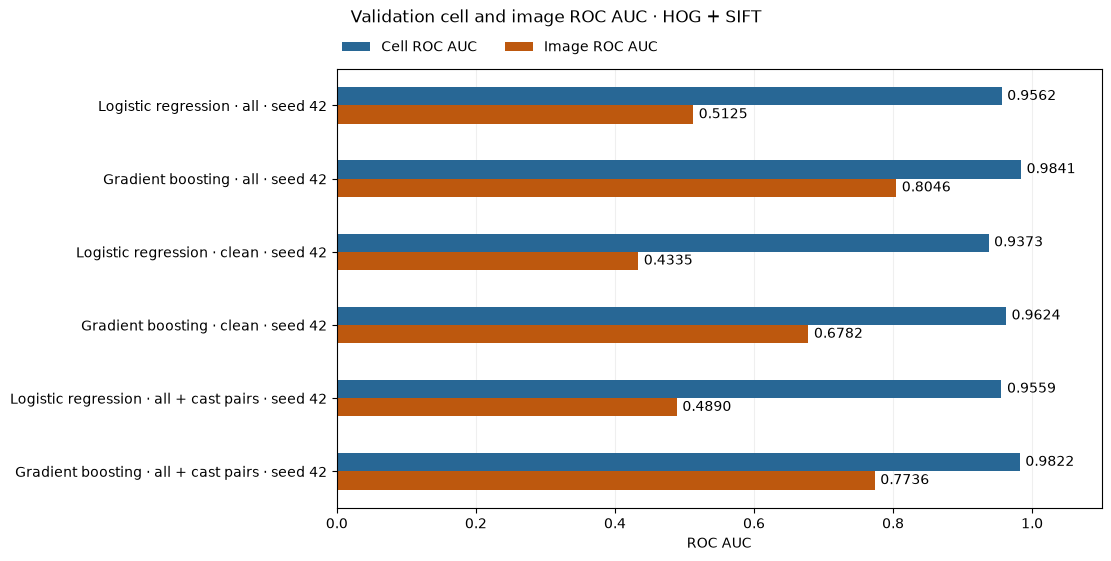

In [ ]:
from matplotlib.patches import Rectangle

FRACTURE_THRESHOLD = 0.5
image_predictions = {}
image_results = []

for run_folder in run_folders:
    with np.load(run_folder / 'val_cell_predictions.npz') as saved:
        rows = saved['rows']
        cell_scores = saved['scores']

    grid_scores = cell_scores.reshape(len(rows), -1)
    top_cell = grid_scores.argmax(axis=1)
    image_scores = grid_scores[np.arange(len(rows)), top_cell]
    predicted = (grid_scores > FRACTURE_THRESHOLD).any(axis=1)
    actual = graz.iloc[rows]['label'].to_numpy()

    run = run_folder.name
    image_predictions[run] = pd.DataFrame({
        'row': rows,
        'actual': actual,
        'score': image_scores,
        'predicted': predicted,
        'top_cell': top_cell,
    })

    image_results.append({
        'run': run,
        'image_auc': roc_auc_score(actual, image_scores),
        'flagged_xrays': int(predicted.sum()),
        'total_xrays': len(rows),
    })

image_results = pd.DataFrame(image_results)
comparison = pd.DataFrame(results).merge(
    image_results, on='run', validate='one_to_one'
)
display(comparison.round(4))

# Compare cell and image AUC with shorter run labels.
plot_data = comparison.set_index('run')[['validation_cell_auc', 'image_auc']].rename(
    columns={'validation_cell_auc': 'Cell ROC AUC', 'image_auc': 'Image ROC AUC'}
)
plot_data.index = (
    plot_data.index
    .str.replace(r'_seed(\d+)$', r' · seed \1', regex=True)
    .str.replace('hog-sift-lr_', 'Logistic regression · ', regex=False)
    .str.replace('hog-sift-gb_', 'Gradient boosting · ', regex=False)
    .str.replace('all-castpairs', 'all + cast pairs', regex=False)
)

fig, ax = plt.subplots(figsize=(11, 5.5), layout='constrained')
plot_data.plot.barh(ax=ax, color=['#286795', '#BD580E'])

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.4f', padding=4)

ax.set(xlabel='ROC AUC', ylabel='', xlim=(0, 1.10))
ax.set_xticks(np.linspace(0, 1, 6))
ax.invert_yaxis()
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.2)
ax.legend(
    loc='lower left',
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False,
    borderaxespad=0,
)
fig.suptitle('Validation cell and image ROC AUC · HOG + SIFT')
plt.show()
best_run = image_results.loc[image_results['image_auc'].idxmax(), 'run']
best_predictions = image_predictions[best_run]

## Locate the fracture on flagged images
For each flagged X-ray, the model uses the highest-scoring cell to draw one box. An unflagged image receives no box.

Compare the predicted box with the fracture annotation it overlaps most. Higher intersection over union (IoU) means better overlap. IoU ranges from 0 for no overlap to 1 for a perfect match. An annotated fracture image that receives no box gets IoU 0. The mean IoU and the fraction reaching 0.5 are calculated over annotated fracture images.

,run,annotated_fracture_images,mean_iou,fraction_iou_at_least_0.5
0,hog-sift-lr_all_seed42,2208,0.3687,0.3909
1,hog-sift-gb_all_seed42,2208,0.4626,0.5457
2,hog-sift-lr_clean_seed42,2208,0.3529,0.3714
3,hog-sift-gb_clean_seed42,2208,0.3686,0.4316
4,hog-sift-lr_all-castpairs_seed42,2208,0.3731,0.3990
5,hog-sift-gb_all-castpairs_seed42,2208,0.4566,0.5408


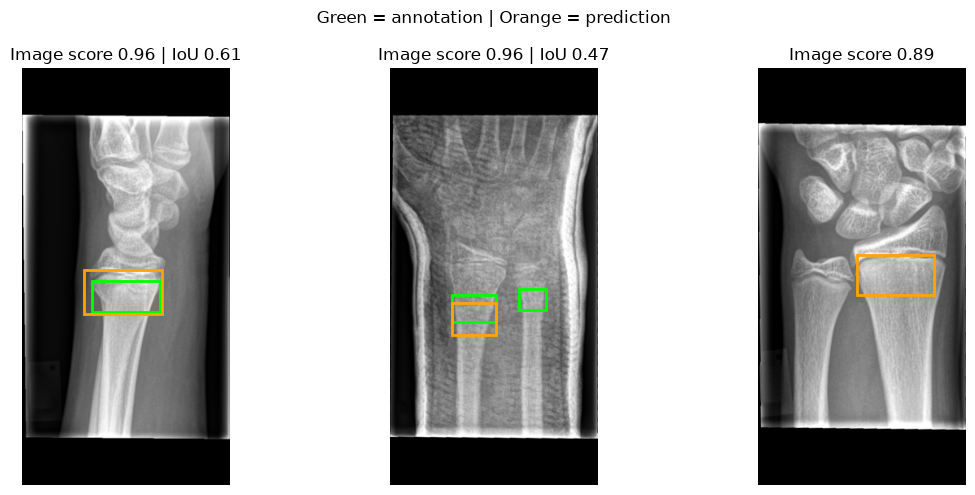

In [ ]:
BOX_COLUMNS = ['x0', 'y0', 'x1', 'y1']
box_annotations = pd.read_csv(PROCESSED_DIR / 'graz_boxes.csv')
fracture_boxes = {
    stem: group[BOX_COLUMNS].to_numpy()
    for stem, group in box_annotations[box_annotations['name'].eq('fracture')].groupby('filestem')
}
def best_iou(box, annotations):
    overlap = np.minimum(box[2:], annotations[:, 2:]) - np.maximum(box[:2], annotations[:, :2])
    intersection = np.prod(np.maximum(overlap, 0), axis=1)
    union = np.prod(box[2:] - box[:2]) + np.prod(
        annotations[:, 2:] - annotations[:, :2], axis=1
    ) - intersection
    return (intersection / union).max()
box_results = []
for run_folder in run_folders:
    predictions = image_predictions[run_folder.name]
    with np.load(run_folder / 'val_cell_predictions.npz') as saved:
        distances_grid = saved['distances'].reshape(len(predictions), -1, 4)
        cell = predictions['top_cell'].to_numpy()
        left, top, right, bottom = distances_grid[np.arange(len(predictions)), cell].T

    grid_row, grid_col = np.divmod(cell, GRID_COLS)
    center_x = (grid_col + 0.5) * CELL_SIZE
    center_y = (grid_row + 0.5) * CELL_SIZE
    flagged = predictions['predicted'].to_numpy()
    boxes = np.full((len(predictions), 4), np.nan)
    decoded = np.column_stack([center_x[flagged] - left[flagged],
                               center_y[flagged] - top[flagged],
                               center_x[flagged] + right[flagged],
                               center_y[flagged] + bottom[flagged]])
    boxes[flagged] = np.clip(decoded, 0, [IMAGE_SHAPE[1], IMAGE_SHAPE[0]] * 2)
    predictions[BOX_COLUMNS] = boxes

    ious = np.full(len(predictions), np.nan)
    for i, row in enumerate(predictions.itertuples(index=False)):
        annotations = fracture_boxes.get(graz.iloc[row.row]['filestem'])
        if row.actual == 1 and annotations is not None:
            ious[i] = best_iou(boxes[i], annotations) if row.predicted else 0.0

    predictions['iou'] = ious
    annotated = ious[np.isfinite(ious)]
    box_results.append({
        'run': run_folder.name, 'annotated_fracture_images': len(annotated),
        'mean_iou': annotated.mean() if len(annotated) else np.nan,
        'fraction_iou_at_least_0.5': (annotated >= 0.5).mean() if len(annotated) else np.nan,
    })

display(pd.DataFrame(box_results).round(4))

examples = pd.concat([
    best_predictions[best_predictions['iou'].ge(0.5)].head(1),
    best_predictions[best_predictions['iou'].lt(0.5)].head(1),
    best_predictions[best_predictions['actual'].eq(0) & best_predictions['predicted']].head(1),
])
if examples.empty:
    examples = best_predictions.head(1)

fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 5), squeeze=False)
for ax, row in zip(axes[0], examples.itertuples(index=False)):
    ax.imshow(images[row.row], cmap='gray', extent=(0, IMAGE_SHAPE[1], IMAGE_SHAPE[0], 0))
    stem = graz.iloc[row.row]['filestem']
    for x0, y0, x1, y1 in fracture_boxes.get(stem, []):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                               edgecolor='lime', linewidth=2))
    if row.predicted:
        ax.add_patch(Rectangle((row.x0, row.y0), row.x1 - row.x0, row.y1 - row.y0,
                               fill=False, edgecolor='orange', linewidth=2))
    iou_text = f' | IoU {row.iou:.2f}' if np.isfinite(row.iou) else ''
    ax.set_title(f'Image score {row.score:.2f}{iou_text}')
    ax.axis('off')
fig.suptitle('Green = annotation | Orange = prediction')
plt.tight_layout()
plt.show()

The green boxes show the annotated fractures and the orange boxes show what the model predicted. In the first X-ray, the predicted box lines up fairly well with the annotation, with an IoU of 0.61. The second X-ray has the same image score of 0.96, but the predicted box only partly overlaps one of the two annotations and misses the other. In the last X-ray, the model gave a score of 0.89 and drew a box even though there was no annotated fracture. 

## Gradient boosting validation curve
The plot shows how image AUC changes across boosting iterations on a sample of 256 validation X-rays. The table shown above uses the full validation split.

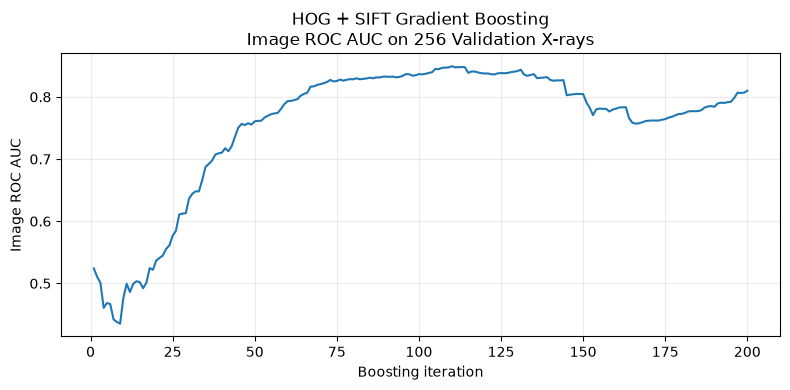

In [12]:
from sklearn.model_selection import train_test_split

gb_results = image_results[image_results['run'].str.startswith('hog-sift-gb_')]
curve_run = gb_results.loc[gb_results['image_auc'].idxmax(), 'run']
curve_rows = val_rows
if len(curve_rows) > 256:
    curve_rows, _ = train_test_split(
        curve_rows, train_size=256, random_state=42,
        stratify=graz.iloc[curve_rows]['label'],
    )

hog_features, sift_features = features
curve_X = np.empty((len(curve_rows) * N_CELLS, HOG_SIZE + SIFT_SIZE), dtype=np.float32)
curve_X[:, :HOG_SIZE] = hog_features[curve_rows].reshape(-1, HOG_SIZE)
curve_X[:, HOG_SIZE:] = sift_features[curve_rows].reshape(-1, SIFT_SIZE)
curve_labels = graz.iloc[curve_rows]['label'].to_numpy()

gb_model = joblib.load(NOTEBOOK_DIR / curve_run / 'objectness_model.joblib')
curve_auc = []
for cell_probabilities in gb_model.staged_predict_proba(curve_X):
    scores = cell_probabilities[:, 1].reshape(len(curve_rows), N_CELLS).max(axis=1)
    curve_auc.append(roc_auc_score(curve_labels, scores))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(curve_auc) + 1), curve_auc)
ax.set(
    xlabel='Boosting iteration',
    ylabel='Image ROC AUC',
    title=f'HOG + SIFT Gradient Boosting\nImage ROC AUC on {len(curve_rows)} Validation X-rays',
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Choosing a fracture cutoff
The image cutoff is tuned for the gradient boosting run with the best validation AUC. Scores are sorted once to count predictions at each cutoff. Using side='right' means an X-ray is flagged only when its score is above the cutoff. The counts change only when the cutoff reaches an observed score. If two cutoffs tie, the one that catches more fractures is selected. The table shows the original cutoff and the cutoff selected on validation.

In [ ]:
gb_runs = image_results[image_results['run'].str.startswith('hog-sift-gb_')]
tuning_run = gb_runs.loc[gb_runs['image_auc'].idxmax(), 'run']
validation = image_predictions[tuning_run]
scores = validation['score'].to_numpy(dtype=float)
actual = validation['actual'].to_numpy() == 1
fracture_scores = np.sort(scores[actual])
normal_scores = np.sort(scores[~actual])

original_cutoff = 0.5
cutoffs = np.unique(np.r_[original_cutoff, scores[scores > original_cutoff]])

fn = np.searchsorted(fracture_scores, cutoffs, side='right')
tn = np.searchsorted(normal_scores, cutoffs, side='right')
tp = len(fracture_scores) - fn
fp = len(normal_scores) - tn

recall = tp / len(fracture_scores)
specificity = tn / len(normal_scores)

threshold_results = pd.DataFrame({
    'Cutoff': cutoffs,
    'Fractures caught': tp,
    'Fractures missed': fn,
    'False alarms': fp,
    'Normal X-rays cleared': tn,
    'Recall': recall,
    'Specificity': specificity,
    'Balanced accuracy': (recall + specificity) / 2,
})

best = threshold_results.sort_values(
    ['Balanced accuracy', 'Recall', 'Cutoff'],
    ascending=[False, False, True],
).iloc[0]
selected_cutoff = float(best['Cutoff'])

examples = [0.50, 0.75, 0.90, 0.95, 0.99]
example_rows = np.searchsorted(cutoffs, examples, side='right') - 1
summary = threshold_results.loc[
    np.unique(np.r_[example_rows, int(best.name)])
].copy()

summary = threshold_results.loc[[0, int(best.name)]].copy()
summary.index = ['Original rule', 'Selected on validation']
print(tuning_run)
display(summary.round(4))
print(f'Exact selected cutoff: {selected_cutoff:.12g}')

hog-sift-gb_all_seed42


,Cutoff,Fractures caught,Fractures missed,False alarms,Normal X-rays cleared,Recall,Specificity,Balanced accuracy
Original rule,0.5000,2208,0,992,2,1.0000,0.0020,0.5010
Selected on validation,0.9529,1511,697,175,819,0.6843,0.8239,0.7541


Exact selected cutoff: 0.95285397768


## Test the selected cutoff
Both cutoffs were compared on the test set. It compares the original 0.5 rule with the selected cutoff using the same saved test scores.

In [ ]:
with np.load(NOTEBOOK_DIR / tuning_run / 'test_cell_predictions.npz') as saved:
    test_rows = saved['rows']
    cell_scores = saved['scores']
test_scores = cell_scores.reshape(len(test_rows), -1).max(axis=1)
actual_fracture = graz.iloc[test_rows]['label'].to_numpy() == 1

test_results = []
for rule, cutoff in [
    ('Original rule', original_cutoff),
    ('Selected on validation', selected_cutoff),
]:
    predicted_fracture = test_scores > cutoff

    test_results.append({
        'Rule': rule,
        'Cutoff': cutoff,
        'Fractures caught': np.sum(actual_fracture & predicted_fracture),
        'Fractures missed': np.sum(actual_fracture & ~predicted_fracture),
        'False alarms': np.sum(~actual_fracture & predicted_fracture),
        'Normal X-rays cleared': np.sum(~actual_fracture & ~predicted_fracture),
        'Recall': predicted_fracture[actual_fracture].mean(),
        'Specificity': (~predicted_fracture[~actual_fracture]).mean(),
    })
print(f'Test image ROC AUC: {roc_auc_score(actual_fracture, test_scores):.4f}')
display(pd.DataFrame(test_results).round(4))

Test image ROC AUC: 0.8250


,Rule,Cutoff,Fractures caught,Fractures missed,False alarms,Normal X-rays cleared,Recall,Specificity
0,Original rule,0.5000,1899,0,1041,3,1.0000,0.0029
1,Selected on validation,0.9529,1312,587,181,863,0.6909,0.8266


## False alarms and missed fractures on the test set
The chart compares the original cutoff of 0.5 with the cutoff selected on validation (0.9529). The higher cutoff reduced false alarms from 1,041 to 181, but it also increased the number of fractured X-rays the model missed from 0 to 587.

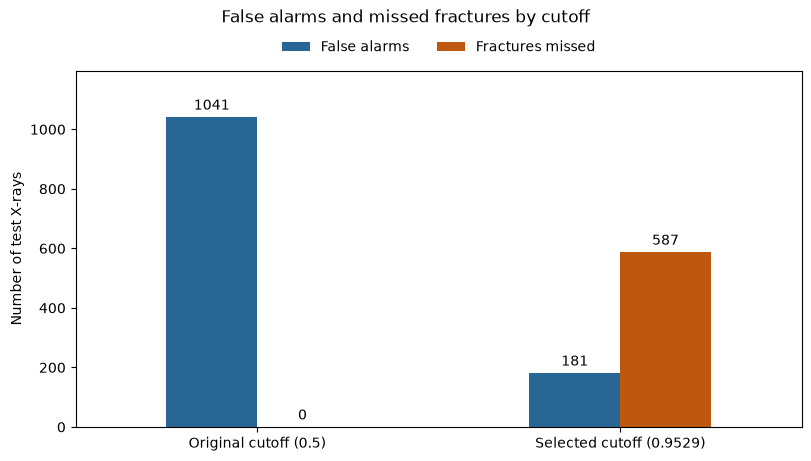

In [15]:
plot_data = pd.DataFrame(test_results).set_index('Rule')[
    ['False alarms', 'Fractures missed']
]
plot_data.index = ['Original cutoff (0.5)', f'Selected cutoff ({selected_cutoff:.4f})']

fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
plot_data.plot.bar(ax=ax, color=['#286795', '#BD580E'], rot=0)

for bars in ax.containers:
    ax.bar_label(bars, padding=3, fmt='%.0f')

ax.set(xlabel='', ylabel='Number of test X-rays')
ax.set_ylim(0, plot_data.to_numpy().max() * 1.15)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
fig.suptitle('False alarms and missed fractures by cutoff')
plt.show()

## Check how the new cutoff affects the boxes
IOU measures how closely the predicted boxes match the fracture annotations. 

In [ ]:
with np.load(NOTEBOOK_DIR / tuning_run / 'test_cell_predictions.npz') as saved:
    rows = saved['rows']
    grid_scores = saved['scores'].reshape(len(rows), -1)
    grid_distances = saved['distances'].reshape(len(rows), -1, 4)

top_cells = grid_scores.argmax(axis=1)
image_scores = grid_scores[np.arange(len(rows)), top_cells]
left, top, right, bottom = grid_distances[np.arange(len(rows)), top_cells].T

grid_row, grid_col = np.divmod(top_cells, GRID_COLS)
x = (grid_col + 0.5) * CELL_SIZE
y = (grid_row + 0.5) * CELL_SIZE
boxes = np.column_stack([x - left, y - top, x + right, y + bottom])
boxes = np.clip(boxes, 0, [IMAGE_SHAPE[1], IMAGE_SHAPE[0]] * 2)

test_metadata = graz.iloc[rows]
box_comparison = []

for rule, cutoff in [
    ('Original rule', original_cutoff),
    ('Selected on validation', selected_cutoff),
]:
    ious = []
    for i, row in enumerate(test_metadata.itertuples(index=False)):
        annotations = fracture_boxes.get(row.filestem)
        if row.label != 1 or annotations is None:
            continue

        if image_scores[i] > cutoff:
            ious.append(best_iou(boxes[i], annotations))
        else:
            ious.append(0.0)

    ious = np.asarray(ious)
    box_comparison.append({
        'Rule': rule,
        'Cutoff': cutoff,
        'Annotated fracture X-rays': len(ious),
        'Mean IoU': ious.mean(),
        'Share with IoU ≥ 0.5': (ious >= 0.5).mean(),
    })
display(pd.DataFrame(box_comparison).round(4))

,Rule,Cutoff,Annotated fracture X-rays,Mean IoU,Share with IoU ≥ 0.5
0,Original rule,0.5000,1899,0.4550,0.5403
1,Selected on validation,0.9529,1899,0.3389,0.4181


With the higher cutoff, fewer fractured X-rays had a box that overlapped the annotation by an IOU of at least 0.5 (41.8% vs. 54.0%).

## Key findings
- HOG + SIFT with gradient boosting performed best, with an image-level ROC AUC of 0.8250 on the test set.
- The higher cutoff reduced false alarms from 1,041 to 181, but the model missed 587 fractured X-rays. The share of fractured X-rays with a box reaching IoU ≥ 0.5 dropped from 54.0% to 41.8%.